 BAND: 20m (14.10 MHz) | 2x2 Sweep: (1-Reel vs Multi-Reel) x (1-Cap vs 2-Cap)
  LMatch_WB2CBA   [1-Reel] (Real Opt: S11=-30.00 dB, S21=-0.348 dB)
    -> MILP Basic  : S11= -8.93 dB, S21=-1.356 dB, FCC=+ 3.6 dB | Spulen-Rollen=1 ($3.00)
    -> ±5% MC (WC) : S11= -4.43 dB, S21=-2.794 dB, FCC=+ 2.2 dB
    -> Bauteile    : Cm=820.0p, Lm=150n, C1=4.7p, L2=150n, C3=1000.0p, L4=150n, C5=4.7p

  LMatch_WB2CBA   [1-Reel] (Real Opt: S11=-30.00 dB, S21=-0.348 dB)
    -> MILP Basic  : S11= -8.93 dB, S21=-1.356 dB, FCC=+ 3.6 dB | Spulen-Rollen=1 ($3.00)
    -> ±5% MC (WC) : S11= -4.43 dB, S21=-2.794 dB, FCC=+ 2.2 dB
    -> Bauteile    : Cm=820.0p, Lm=150n, C1=4.7p, L2=150n, C3=1000.0p, L4=150n, C5=4.7p

  LMatch_WB2CBA   [Multi-Reel] (Real Opt: S11=-31.04 dB, S21=-0.380 dB)
    -> MILP Basic  : S11=-27.50 dB, S21=-0.397 dB, FCC=+ 3.4 dB | Spulen-Rollen=2 ($6.00)
    -> ±5% MC (WC) : S11=-14.91 dB, S21=-0.580 dB, FCC=+ 1.2 dB
    -> Bauteile    : Cm=20.0p, Lm=100n, C1=220.0p, L2=680n, C3=430.0p, L4=

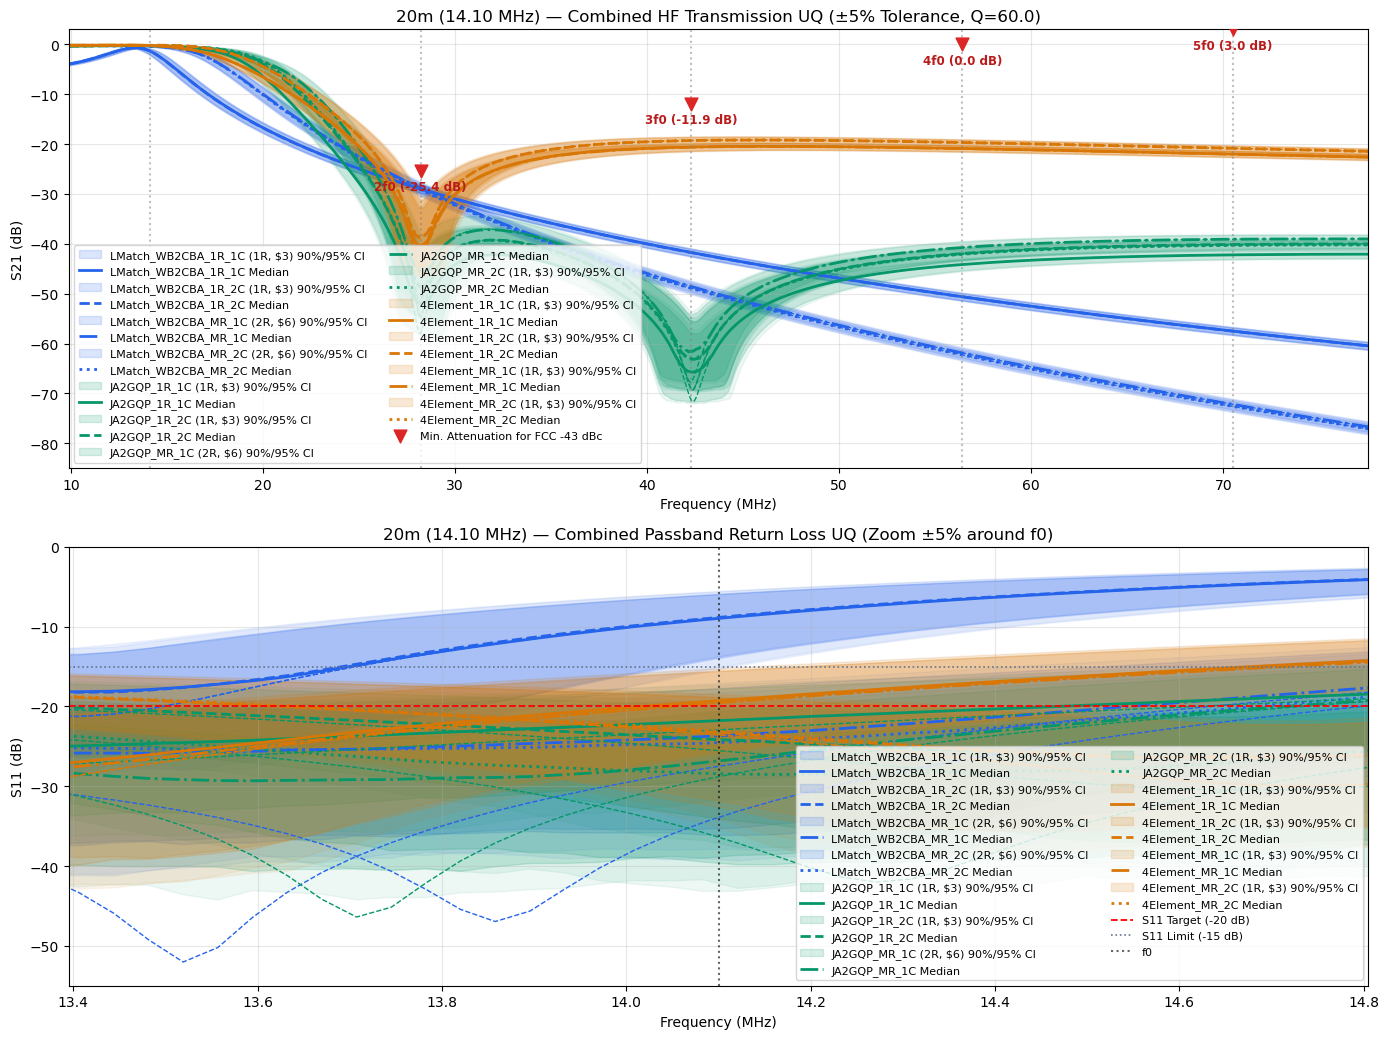

 BAND: 40m (7.05 MHz) | 2x2 Sweep: (1-Reel vs Multi-Reel) x (1-Cap vs 2-Cap)
  LMatch_WB2CBA   [1-Reel] (Real Opt: S11=-30.00 dB, S21=-0.345 dB)
    -> MILP Basic  : S11= -4.41 dB, S21=-3.351 dB, FCC=+ 3.2 dB | Spulen-Rollen=1 ($3.00)
    -> ±5% MC (WC) : S11= -3.55 dB, S21=-3.976 dB, FCC=+ 1.8 dB
    -> Bauteile    : Cm=1200.0p, Lm=270n, C1=4.7p, L2=270n, C3=3000.0p, L4=270n, C5=4.7p

  LMatch_WB2CBA   [1-Reel] (Real Opt: S11=-30.00 dB, S21=-0.345 dB)
    -> MILP Basic  : S11= -1.13 dB, S21=-6.624 dB, FCC=+ 3.6 dB | Spulen-Rollen=1 ($3.00)
    -> ±5% MC (WC) : S11= -0.94 dB, S21=-7.327 dB, FCC=+ 2.2 dB
    -> Bauteile    : Cm=560.0p+3000.0p, Lm=330n, C1=4.7p, L2=330n, C3=910.0p, L4=330n, C5=4.7p

  LMatch_WB2CBA   [Multi-Reel] (Real Opt: S11=-32.57 dB, S21=-0.387 dB)
    -> MILP Basic  : S11=-20.44 dB, S21=-0.519 dB, FCC=+ 6.5 dB | Spulen-Rollen=2 ($6.00)
    -> ±5% MC (WC) : S11=-12.18 dB, S21=-0.833 dB, FCC=+ 4.2 dB
    -> Bauteile    : Cm=39.0p, Lm=330n, C1=470.0p, L2=1500n, C3=820

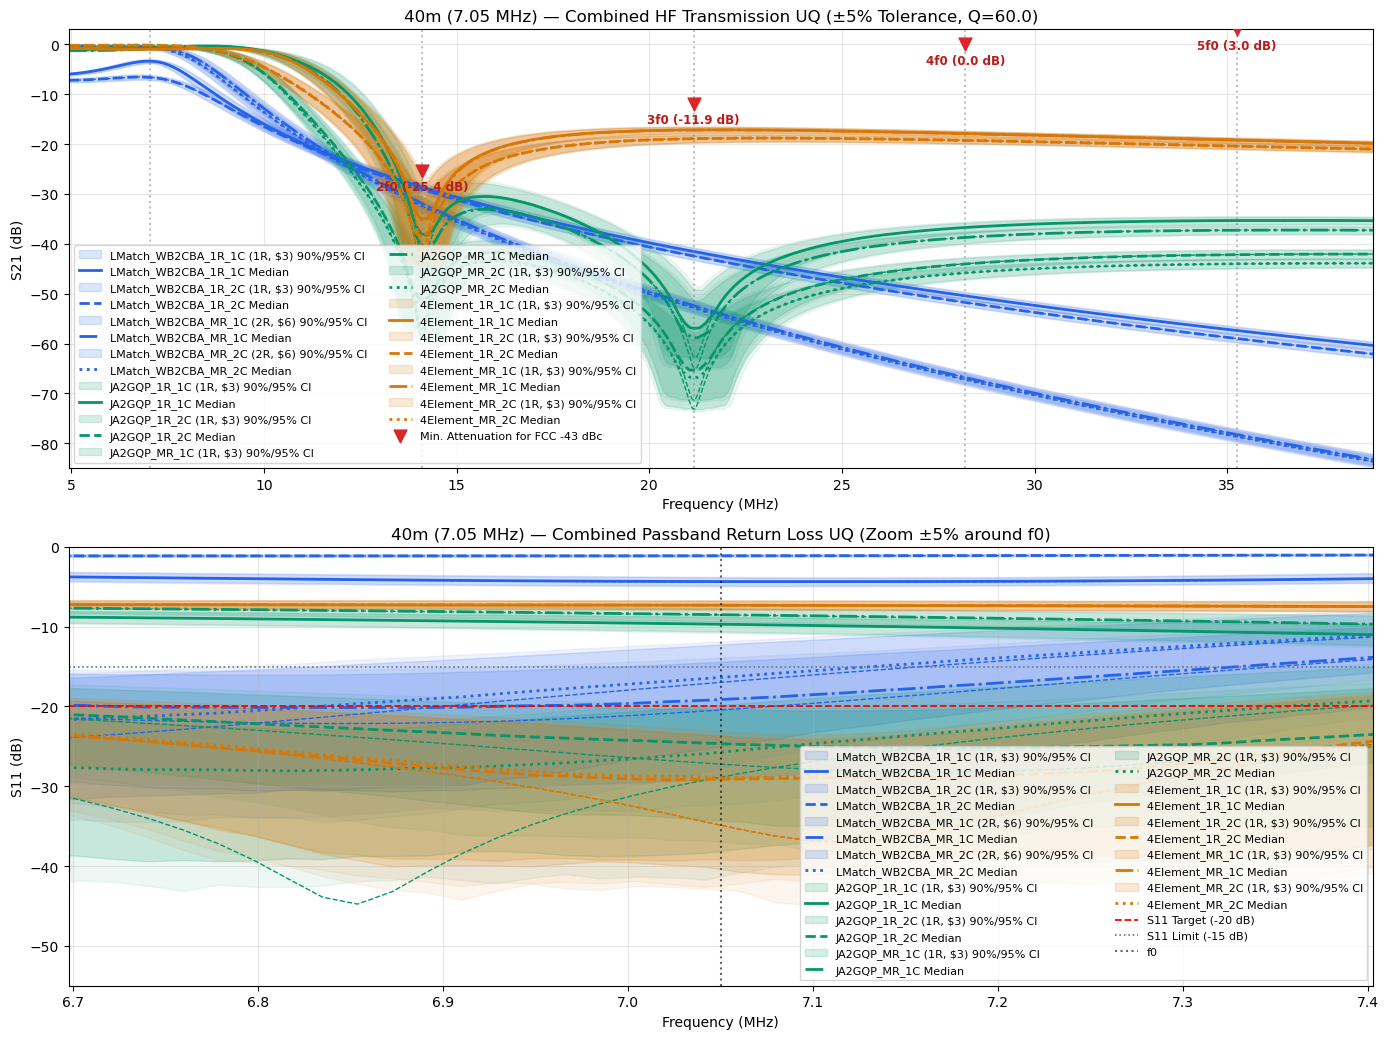

In [1]:
import numpy as np
from scipy.optimize import minimize, milp, LinearConstraint, Bounds
import matplotlib.pyplot as plt

# Standard E12 & E24 Reihen (JLCPCB Basic C0G/NP0 Kondensatoren & Wirewound Induktivitäten)
E12 = np.array([1.0, 1.2, 1.5, 1.8, 2.2, 2.7, 3.3, 3.9, 4.7, 5.6, 6.8, 8.2])
E24 = np.array([1.0, 1.1, 1.2, 1.3, 1.5, 1.6, 1.8, 2.0, 2.2, 2.4, 2.7, 3.0,
                3.3, 3.6, 3.9, 4.3, 4.7, 5.1, 5.6, 6.2, 6.8, 7.5, 8.2, 9.1])

CAP_POOL = np.concatenate([E24 * d for d in [1e-12, 10e-12, 100e-12, 1e-9]])
CAP_POOL = CAP_POOL[(CAP_POOL >= 4.7e-12) & (CAP_POOL <= 3300e-12)]

IND_POOL = np.concatenate([E12 * d for d in [10e-9, 100e-9, 1e-6]])
IND_POOL = IND_POOL[(IND_POOL >= 47e-9) & (IND_POOL <= 2200e-9)]

# --- ABCD-Zweitor-Bausteine ---
def abcd_shunt_c(C, w, Q_c=1000.0):
    Y = 1j * w * C + (w * C / Q_c)
    return np.array([[1.0, 0.0], [Y, 1.0]], dtype=complex)

def abcd_series_l(L, w, Q_l=60.0):
    Z = (w * L / Q_l) + 1j * w * L
    return np.array([[1.0, Z], [0.0, 1.0]], dtype=complex)

def abcd_notch_lc(L, C, w, Q_l=60.0):
    Z_l = (w * L / Q_l) + 1j * w * L
    Z = 1.0 / (1.0 / Z_l + 1j * w * C)
    return np.array([[1.0, Z], [0.0, 1.0]], dtype=complex)

def eval_abcd(M, Zs=50.0, Zl=50.0):
    A, B, C, D = M.item((0, 0)), M.item((0, 1)), M.item((1, 0)), M.item((1, 1))
    denom = A * Zl + B + C * Zs * Zl + D * Zs
    s21 = float(10.0 * np.log10(4.0 * Zs * Zl / (np.abs(denom)**2) + 1e-18))
    Zin = (A * Zl + B) / (C * Zl + D)
    s11 = float(20.0 * np.log10(np.abs((Zin - Zs) / (Zin + Zs)) + 1e-18))
    return s21, s11

# --- Topologie-Definitionen ---
def cascade_topology(topo, x, w, Q_l):
    if topo == "LMatch_WB2CBA":
        cm, lm, c1, l2, c3, l4, c5 = x
        return (abcd_shunt_c(cm, w) @ abcd_series_l(lm, w, Q_l) @
                abcd_shunt_c(c1, w) @ abcd_series_l(l2, w, Q_l) @
                abcd_shunt_c(c3, w) @ abcd_series_l(l4, w, Q_l) @
                abcd_shunt_c(c5, w))
    elif topo == "JA2GQP":
        c1, l1, c2, c3, l2, c4, c5 = x
        return (abcd_shunt_c(c1, w) @ abcd_notch_lc(l1, c2, w, Q_l) @
                abcd_shunt_c(c3, w) @ abcd_notch_lc(l2, c4, w, Q_l) @
                abcd_shunt_c(c5, w))
    elif topo == "4Element":
        # 4-Element Notch LPF: C1 -> (L2 || C2) -> C3 (Notch bei 2*f0!)
        c1, l2, c2, c3 = x
        return (abcd_shunt_c(c1, w) @ abcd_notch_lc(l2, c2, w, Q_l) @
                abcd_shunt_c(c3, w))
    raise ValueError(f"Unbekannte Topologie: {topo}")


TOPO_SPECS = {
    "LMatch_WB2CBA": {
        "names": ["Cm", "Lm", "C1", "L2", "C3", "L4", "C5"],
        "is_ind": [False, True, False, True, False, True, False],
        "seed": [120e-12, 100e-9, 180e-12, 560e-9, 390e-12, 560e-9, 180e-12],
        "color": "#2563eb",
    },
    "JA2GQP": {
        "names": ["C1", "L1", "C2", "C3", "L2", "C4", "C5"],
        "is_ind": [False, True, False, False, True, False, False],
        "seed": [200e-12, 390e-9, 82e-12, 360e-12, 390e-9, 33e-12, 150e-12],
        "color": "#059669",
    },
    "4Element": {
        "names": ["C1", "L2", "C2", "C3"],
        "is_ind": [False, True, False, False],
        "seed": [270e-12, 560e-9, 56e-12, 270e-12],
        "color": "#d97706",
    },
}

def solve_topology_mip(topo, f0, Zs=50.0, Zl=50.0, harm_dbc=(-17.6, -31.1, -43.0, -46.0),
                       Q_l=60.0, fcc_limit=-43.0, max_caps_per_node=2, reel_penalty=0.35, max_reels=None):
    spec = TOPO_SPECS[topo]
    names, is_ind = spec["names"], spec["is_ind"]
    n_comp = len(is_ind)
    ind_indices = [i for i, ind in enumerate(is_ind) if ind]
    scale = 14.1e6 / f0
    x_init = np.array(spec["seed"]) * scale

    lo_b = np.array([IND_POOL.min() if ind else CAP_POOL.min() for ind in is_ind])
    hi_b = np.array([IND_POOL.max() if ind else (max_caps_per_node * CAP_POOL.max()) for ind in is_ind])
    x_init = np.clip(x_init, lo_b * 1.05, hi_b * 0.95)

    w0 = 2.0 * np.pi * f0
    w_lo, w_hi = 0.94 * w0, 1.06 * w0
    w_harms = [k * w0 for k in range(2, 2 + len(harm_dbc))]
    target_margin = 3.0

    def eval_net(x):
        s21_0, s11_0 = eval_abcd(cascade_topology(topo, x, w0, Q_l), Zs, Zl)
        margins = []
        for wh, hl in zip(w_harms, harm_dbc):
            s21_h, _ = eval_abcd(cascade_topology(topo, x, wh, Q_l), Zs, Zl)
            margins.append(fcc_limit - (hl + s21_h))
        return s21_0, s11_0, float(min(margins))

    def unpack_u(u):
        if max_reels == 1 and len(ind_indices) > 1:
            x = np.empty(n_comp)
            l_shared = float(np.exp(u.item(0)))
            u_idx = 1
            for i, ind in enumerate(is_ind):
                if ind:
                    x[i] = l_shared
                else:
                    x[i] = float(np.exp(u.item(u_idx)))
                    u_idx += 1
            return x
        return np.exp(u)

    if max_reels == 1 and len(ind_indices) > 1:
        l_geom = float(np.prod([x_init.item(i) for i in ind_indices]) ** (1.0 / len(ind_indices)))
        u0 = np.log([l_geom] + [x_init.item(i) for i, ind in enumerate(is_ind) if not ind])
    else:
        u0 = np.log(x_init)

    def obj_nlp(u):
        x = unpack_u(u)
        bound_pen = np.sum(np.maximum(0.0, lo_b - x) / lo_b + np.maximum(0.0, x - hi_b) / hi_b)**2 * 5000.0
        x_c = np.clip(x, lo_b, hi_b)
        s21, s11, min_m = eval_net(x_c)
        _, s11_lo = eval_abcd(cascade_topology(topo, x_c, w_lo, Q_l), Zs, Zl)
        _, s11_hi = eval_abcd(cascade_topology(topo, x_c, w_hi, Q_l), Zs, Zl)
        pen = (bound_pen +
               max(0.0, target_margin - min_m)**2 * 40.0 +
               max(0.0, -0.40 - s21)**2 * 300.0 +
               max(0.0, s11 + 25.0)**2 * 30.0 +
               max(0.0, s11_lo + 22.0)**2 * 15.0 +
               max(0.0, s11_hi + 22.0)**2 * 15.0)
        if topo == "JA2GQP":
            f_n1 = 1.0 / (2.0 * np.pi * np.sqrt(x_c.item(1) * x_c.item(2)))
            f_n2 = 1.0 / (2.0 * np.pi * np.sqrt(x_c.item(4) * x_c.item(5)))
            pen += ((f_n1 - 2 * f0) / f0)**2 * 400.0 + ((f_n2 - 3 * f0) / f0)**2 * 400.0
        elif topo == "4Element":
            f_n1 = 1.0 / (2.0 * np.pi * np.sqrt(x_c.item(1) * x_c.item(2)))
            pen += ((f_n1 - 2 * f0) / f0)**2 * 400.0
        return float(2.0 * max(s11, -30.0) + pen)

    res_nlp = minimize(obj_nlp, u0, method="Nelder-Mead",
                       options={"maxiter": 6000, "xatol": 1e-5, "fatol": 1e-4})
    x_star = np.clip(unpack_u(res_nlp.x), lo_b, hi_b)
    s21_real, s11_real, m_real = eval_net(x_star)

    u_star = np.log(x_star)
    eps = 1e-3
    J_s11 = np.zeros(n_comp)
    J_m = np.zeros(n_comp)
    for i in range(n_comp):
        du = np.zeros(n_comp)
        du[i] = eps
        _, s11_p, m_p = eval_net(np.exp(u_star + du))
        _, s11_n, m_n = eval_net(np.exp(u_star - du))
        J_s11[i] = (s11_p - s11_n) / (2.0 * eps)
        J_m[i] = (m_p - m_n) / (2.0 * eps)

    # Diskrete Knoten-Kandidaten (1x E24 oder 2x E24 parallel)
    cap_cands = list(CAP_POOL)
    cap_labels = [f"{c*1e12:.1f}p" for c in CAP_POOL]
    if max_caps_per_node >= 2:
        for idx1 in range(len(CAP_POOL)):
            for idx2 in range(idx1, len(CAP_POOL)):
                c_sum = CAP_POOL.item(idx1) + CAP_POOL.item(idx2)
                if c_sum <= max_caps_per_node * CAP_POOL.max():
                    cap_cands.append(c_sum)
                    cap_labels.append(f"{CAP_POOL.item(idx1)*1e12:.1f}p+{CAP_POOL.item(idx2)*1e12:.1f}p")
    CAP_NODE_POOL = np.array(cap_cands)

    Nc, Nl = len(CAP_NODE_POOL), len(IND_POOL)
    offsets, cur = [], 0
    for ind in is_ind:
        offsets.append(cur)
        cur += Nl if ind else Nc
    idx_u = cur
    idx_s11 = idx_u + Nl
    idx_sm = idx_s11 + 1

    notch_pairs = []
    if topo == "JA2GQP":
        notch_pairs = [(1, 2, 2.0 * f0), (4, 5, 3.0 * f0)]
    elif topo == "4Element":
        notch_pairs = [(1, 2, 2.0 * f0)]
    idx_notch_slack = idx_sm + 1
    n_vars = idx_notch_slack + len(notch_pairs)

    integrality = np.ones(n_vars)
    integrality[idx_s11:] = 0  # kontinuierliche Slacks

    lb_vars = np.zeros(n_vars)
    ub_vars = np.ones(n_vars)
    ub_vars[idx_s11:] = np.inf

    c_obj = np.zeros(n_vars)
    for i, (ind, target) in enumerate(zip(is_ind, x_star)):
        pool = IND_POOL if ind else CAP_NODE_POOL
        par_pen = np.array([0.0 if ind else (0.04 if "+" in cap_labels[k] else 0.0) for k in range(len(pool))])
        w_dev = 1.5 if ind else 1.0
        c_obj[offsets[i]:offsets[i] + len(pool)] = w_dev * np.abs(np.log(pool / target)) + par_pen
    c_obj[idx_u:idx_u + Nl] = reel_penalty
    c_obj[idx_s11] = 20.0
    c_obj[idx_sm] = 15.0
    for j in range(len(notch_pairs)):
        c_obj[idx_notch_slack + j] = 250.0  # Notch-Abweichung stark bestrafen, aber niemals infeasible!

    rows, lb, ub = [], [], []

    # (A) Exakt 1 diskreter Kandidat pro Bauteil (One-Hot)
    for i, ind in enumerate(is_ind):
        pool = IND_POOL if ind else CAP_NODE_POOL
        r = np.zeros(n_vars)
        r[offsets[i]:offsets[i] + len(pool)] = 1.0
        rows.append(r)
        lb.append(1.0)
        ub.append(1.0)

    # (B) Reel-Kopplung: b[i, k] - u_reel[k] <= 0
    for i, ind in enumerate(is_ind):
        if ind:
            for k in range(Nl):
                r = np.zeros(n_vars)
                r[offsets[i] + k] = 1.0
                r[idx_u + k] = -1.0
                rows.append(r)
                lb.append(-np.inf)
                ub.append(0.0)

    # (C) Optional max_reels: 1 <= sum(u_reel) <= max_reels
    if max_reels is not None:
        r = np.zeros(n_vars)
        r[idx_u:idx_u + Nl] = 1.0
        rows.append(r)
        lb.append(1.0)
        ub.append(float(max_reels))

    # (D) Exakte Log-Notch-Kopplung mit Soft-Slack: |log(L) + log(C) + 2*log(w_n)| <= slack_notch
    for j, (idx_l, idx_c, f_n) in enumerate(notch_pairs):
        log_lc_target = -2.0 * np.log(2.0 * np.pi * f_n)
        r1 = np.zeros(n_vars)
        r1[offsets[idx_l]:offsets[idx_l] + Nl] = np.log(IND_POOL)
        r1[offsets[idx_c]:offsets[idx_c] + Nc] = np.log(CAP_NODE_POOL)
        r1[idx_notch_slack + j] = -1.0
        rows.append(r1); lb.append(-np.inf); ub.append(log_lc_target)

        r2 = np.zeros(n_vars)
        r2[offsets[idx_l]:offsets[idx_l] + Nl] = -np.log(IND_POOL)
        r2[offsets[idx_c]:offsets[idx_c] + Nc] = -np.log(CAP_NODE_POOL)
        r2[idx_notch_slack + j] = -1.0
        rows.append(r2); lb.append(-np.inf); ub.append(-log_lc_target)

    # (E) Log-Space RF S11-Sensitivität mit Soft-Slack
    r_s11 = np.zeros(n_vars)
    for i, (ind, u0_i) in enumerate(zip(is_ind, u_star)):
        pool = IND_POOL if ind else CAP_NODE_POOL
        r_s11[offsets[i]:offsets[i] + len(pool)] = J_s11.item(i) * (np.log(pool) - u0_i)
    r_s11[idx_s11] = -1.0
    rows.append(r_s11); lb.append(-np.inf); ub.append(-22.0 - s11_real)

    # (F) Log-Space RF FCC-Margin-Sensitivität mit Soft-Slack
    r_m = np.zeros(n_vars)
    for i, (ind, u0_i) in enumerate(zip(is_ind, u_star)):
        pool = IND_POOL if ind else CAP_NODE_POOL
        r_m[offsets[i]:offsets[i] + len(pool)] = J_m.item(i) * (np.log(pool) - u0_i)
    r_m[idx_sm] = 1.0
    rows.append(r_m); lb.append(target_margin - m_real); ub.append(np.inf)

    sol = milp(c=c_obj, integrality=integrality,
               bounds=Bounds(lb_vars, ub_vars),
               constraints=LinearConstraint(np.array(rows), lb, ub))

    tag = "1-Reel" if max_reels == 1 else "Multi-Reel"
    if not sol.success:
        print(f"  {topo:<15} [{tag}]: MILP solver error ({sol.message})")
        return None

    v = np.round(sol.x[:idx_s11]).astype(int)
    x_disc, part_strs = [], []
    for i, (ind, nm) in enumerate(zip(is_ind, names)):
        pool = IND_POOL if ind else CAP_NODE_POOL
        sel = v[offsets[i]:offsets[i] + len(pool)]
        k_sel = int(np.argmax(sel))
        x_disc.append(float(pool[k_sel]))
        lbl = f"{pool[k_sel]*1e9:.0f}n" if ind else cap_labels[k_sel]
        part_strs.append(f"{nm}={lbl}")

    n_reels = int(np.sum(v[idx_u:idx_u + Nl]))
    s21_d, s11_d, m_d = eval_net(x_disc)
    wc_s11, wc_s21, wc_m = run_mc(topo, x_disc, f0, Zs, Zl, harm_dbc, Q_l=Q_l, fcc_limit=fcc_limit)

    print(f"  {topo:<15} [{tag}] (Real Opt: S11={s11_real:6.2f} dB, S21={s21_real:6.3f} dB)")
    print(f"    -> MILP Basic  : S11={s11_d:6.2f} dB, S21={s21_d:6.3f} dB, FCC=+{m_d:4.1f} dB | "
          f"Spulen-Rollen={n_reels} (${3*n_reels:.2f})")
    print(f"    -> ±5% MC (WC) : S11={wc_s11:6.2f} dB, S21={wc_s21:6.3f} dB, FCC=+{wc_m:4.1f} dB")
    print(f"    -> Bauteile    : {', '.join(part_strs)}\n")
    return x_disc, n_reels

# --- Monte-Carlo-Verifikation (±5 % auf alle L & C) ---
def run_mc(topo, x_nom, f0, Zs, Zl, harm_dbc, Q_l=60.0, fcc_limit=-43.0, tol=0.05, n_runs=5000):
    rng = np.random.default_rng(42)
    x_arr = np.asarray(x_nom, dtype=float)
    X_mc = x_arr[None, :] * rng.uniform(1.0 - tol, 1.0 + tol, (n_runs, len(x_arr)))
    freqs = np.array([f0] + [k * f0 for k in range(2, 2 + len(harm_dbc))])

    s21_db, s11_db = eval_abcd_vec(topo, X_mc, freqs, Zs=Zs, Zl=Zl, Q_l=Q_l)

    wc_s11 = float(np.max(s11_db[:, 0]))
    wc_s21 = float(np.min(s21_db[:, 0]))
    harm_arr = np.asarray(harm_dbc)[None, :]
    margins = fcc_limit - (harm_arr + s21_db[:, 1:])
    wc_m = float(np.min(margins))
    return wc_s11, wc_s21, wc_m

def eval_abcd_vec(topo, X, freqs, Zs=50.0, Zl=50.0, Q_l=60.0, Q_c=1000.0):
    """
    Vectorized 2x2 ABCD cascade over X shape (N_runs, N_comp) and freqs shape (N_freq,).
    Returns s21_db, s11_db each of shape (N_runs, N_freq).
    """
    w = (2.0 * np.pi * freqs)[None, :]  # (1, F)
    N = X.shape[0]
    F = freqs.shape[0]

    A = np.ones((N, F), dtype=complex)
    B = np.zeros((N, F), dtype=complex)
    C = np.zeros((N, F), dtype=complex)
    D = np.ones((N, F), dtype=complex)

    def mul_shunt_c(c_val):
        nonlocal A, B, C, D
        c_col = c_val[:, None]
        Y = 1j * w * c_col + (w * c_col / Q_c)
        # [A B; C D] @ [1 0; Y 1] = [A + B*Y, B; C + D*Y, D]
        A = A + B * Y
        C = C + D * Y

    def mul_series_l(l_val):
        nonlocal A, B, C, D
        l_col = l_val[:, None]
        Z = (w * l_col / Q_l) + 1j * w * l_col
        # [A B; C D] @ [1 Z; 0 1] = [A, A*Z + B; C, C*Z + D]
        B = A * Z + B
        D = C * Z + D

    def mul_notch_lc(l_val, c_val):
        nonlocal A, B, C, D
        l_col = l_val[:, None]
        c_col = c_val[:, None]
        Z_l = (w * l_col / Q_l) + 1j * w * l_col
        Z = 1.0 / (1.0 / Z_l + 1j * w * c_col)
        B = A * Z + B
        D = C * Z + D

    if topo == "LMatch_WB2CBA":
        mul_shunt_c(X[:, 0]); mul_series_l(X[:, 1])
        mul_shunt_c(X[:, 2]); mul_series_l(X[:, 3])
        mul_shunt_c(X[:, 4]); mul_series_l(X[:, 5])
        mul_shunt_c(X[:, 6])
    elif topo == "JA2GQP":
        mul_shunt_c(X[:, 0]); mul_notch_lc(X[:, 1], X[:, 2])
        mul_shunt_c(X[:, 3]); mul_notch_lc(X[:, 4], X[:, 5])
        mul_shunt_c(X[:, 6])
    elif topo == "4Element":
        mul_shunt_c(X[:, 0]); mul_notch_lc(X[:, 1], X[:, 2])
        mul_shunt_c(X[:, 3])
    else:
        raise ValueError(topo)

    denom = A * Zl + B + C * Zs * Zl + D * Zs
    s21_db = 10.0 * np.log10(4.0 * Zs * Zl / (np.abs(denom)**2) + 1e-18)
    Zin = (A * Zl + B) / (C * Zl + D)
    s11_db = 20.0 * np.log10(np.abs((Zin - Zs) / (Zin + Zs)) + 1e-18)
    return s21_db, s11_db


def plot_band_uq(band_name, results_dict, f0, Zs=50.0, Zl=50.0,
                 harm_dbc=(-17.6, -31.1, -43.0, -46.0), fcc_limit=-43.0,
                 Q_l=60.0, tol=0.05, n_runs=2000):
    rng = np.random.default_rng(42)
    freqs = np.linspace(0.7 * f0, 5.5 * f0, 1800)
    f_mhz = freqs / 1e6

    mode_styles = {"1R_1C": "-", "1R_2C": "--", "MR_1C": "-.", "MR_2C": ":"}
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10.5))

    for label, res in results_dict.items():
        if res is None:
            continue
        x_nom, n_reels = res
        x_arr = np.asarray(x_nom, dtype=float)

        # Parse topology name and optional mode suffix
        ls_med = "-"
        base_topo = label
        for tag, style in mode_styles.items():
            if label.endswith("_" + tag):
                base_topo = label[:-(len(tag) + 1)]
                ls_med = style
                break
        if label.endswith("_Multi"):
            base_topo = label[:-6]
            ls_med = ":"
        elif label.endswith("_1Reel"):
            base_topo = label[:-6]
            ls_med = "-"

        col = TOPO_SPECS[base_topo]["color"]

        # Vectorized Monte Carlo (2,000 runs x 1,800 freqs in ~35 ms)
        X_mc = x_arr[None, :] * rng.uniform(1.0 - tol, 1.0 + tol, (n_runs, len(x_arr)))
        s21, s11 = eval_abcd_vec(base_topo, X_mc, freqs, Zs=Zs, Zl=Zl, Q_l=Q_l)
        s21_nom, s11_nom = eval_abcd_vec(base_topo, x_arr[None, :], freqs, Zs=Zs, Zl=Zl, Q_l=Q_l)
        s21_nom, s11_nom = s21_nom[0], s11_nom[0]

        p2_5_s21, p5_s21, p50_s21, p95_s21, p97_5_s21 = np.percentile(s21, [2.5, 5, 50, 95, 97.5], axis=0)
        p2_5_s11, p5_s11, p50_s11, p95_s11, p97_5_s11 = np.percentile(s11, [2.5, 5, 50, 95, 97.5], axis=0)

        lbl_base = f"{label} ({n_reels}R, ${3*n_reels})"

        # Top: S21 UQ
        ax1.fill_between(f_mhz, p2_5_s21, p97_5_s21, alpha=0.07, color=col)
        ax1.fill_between(f_mhz, p5_s21, p95_s21, alpha=0.16, color=col, label=f"{lbl_base} 90%/95% CI")
        ax1.plot(f_mhz, s21_nom, "--", color=col, lw=1.0)
        ax1.plot(f_mhz, p50_s21, color=col, ls=ls_med, lw=2.0, label=f"{label} Median")

        # Bottom: S11 Passband UQ
        ax2.fill_between(f_mhz, p2_5_s11, p97_5_s11, alpha=0.07, color=col)
        ax2.fill_between(f_mhz, p5_s11, p95_s11, alpha=0.16, color=col, label=f"{lbl_base} 90%/95% CI")
        ax2.plot(f_mhz, s11_nom, "--", color=col, lw=1.0)
        ax2.plot(f_mhz, p50_s11, color=col, ls=ls_med, lw=2.0, label=f"{label} Median")

    for n in range(1, 6):
        ax1.axvline(n * f0 / 1e6, color="grey", ls=":", alpha=0.5)
    harm_freqs = [(k * f0) / 1e6 for k in range(2, 2 + len(harm_dbc))]
    req_atten = [fcc_limit - hl for hl in harm_dbc]
    ax1.scatter(harm_freqs, req_atten, color="#dc2626", marker="v", s=85, zorder=6,
                label="Min. Attenuation for FCC -43 dBc")
    for hf, ra, k in zip(harm_freqs, req_atten, range(2, 6)):
        ax1.annotate(f"{k}f0 ({ra:.1f} dB)", (hf, ra), textcoords="offset points",
                     xytext=(0, -14), ha="center", fontsize=8.5, color="#b91c1c", fontweight="bold")

    ax1.set_title(f"{band_name} — Combined HF Transmission UQ (±5% Tolerance, Q={Q_l})")
    ax1.set_xlabel("Frequency (MHz)")
    ax1.set_ylabel("S21 (dB)")
    ax1.set_ylim(-85, 3)
    ax1.set_xlim(0.7 * f0 / 1e6, 5.5 * f0 / 1e6)
    ax1.grid(alpha=0.3)
    ax1.legend(loc="lower left", fontsize=8.0, ncol=2)

    ax2.axhline(-20.0, color="red", ls="--", lw=1.3, label="S11 Target (-20 dB)")
    ax2.axhline(-15.0, color="#64748b", ls=":", lw=1.2, label="S11 Limit (-15 dB)")
    ax2.axvline(f0 / 1e6, color="black", ls=":", alpha=0.6, label="f0")
    ax2.set_xlim(0.95 * f0 / 1e6, 1.05 * f0 / 1e6)
    ax2.set_ylim(-55, 0)
    ax2.set_title(f"{band_name} — Combined Passband Return Loss UQ (Zoom ±5% around f0)")
    ax2.set_xlabel("Frequency (MHz)")
    ax2.set_ylabel("S11 (dB)")
    ax2.grid(alpha=0.3)
    ax2.legend(loc="lower right", fontsize=8.0, ncol=2)

    plt.tight_layout()
    plt.show()

MODES = [
    ("1R_1C", 1, 1, "-"),
    ("1R_2C", 1, 2, "--"),
    ("MR_1C", None, 1, "-."),
    ("MR_2C", None, 2, ":"),
]

for band_name, f0 in [("20m (14.10 MHz)", 14.1e6), ("40m (7.05 MHz)", 7.05e6)]:
    print("==========================================================================")
    print(f" BAND: {band_name} | 2x2 Sweep: (1-Reel vs Multi-Reel) x (1-Cap vs 2-Cap)")
    print("==========================================================================")
    band_results = {}
    for topo in ["LMatch_WB2CBA", "JA2GQP", "4Element"]:
        for tag, m_reels, m_caps, _ in MODES:
            res = solve_topology_mip(topo, f0, Zs=50.0, Zl=50.0,
                                     max_reels=m_reels, max_caps_per_node=m_caps)
            if res is not None:
                band_results[f"{topo}_{tag}"] = res
    plot_band_uq(band_name, band_results, f0, Zs=50.0, Zl=50.0, Q_l=60.0)